# Role 4 – Explaining the models

What drives the predictions of the two reference models?

1. **Role 2 Random Forest** (seed 0): SHAP values for the test set. Which features matter? Do they behave differently before and after the dark-market shutdown at step 43?
2. **Role 3 GCN** (seed 0): a graph ablation (remove the edges, keep the weights) and GNNExplainer for confidently flagged illicit transactions. How much does the GCN rely on the graph?

The Elliptic features are anonymised. They are referred to by number only. `feature_1`–`feature_93` describe the transaction itself (**local**). `feature_94`–`feature_165` summarise its one-hop neighbours (**aggregated**). The data card has more detail.

**Run:** top to bottom, in Colab or locally. It runs on CPU in about 10 minutes. Model settings are copied from the Role 2 and Role 3 notebooks. Explanations describe what these models learned. They are not evidence that any transaction was illicit.

## 1. Data and the shared split

In [1]:
%pip -q install kagglehub shap torch_geometric

import sys, random
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import kagglehub

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = Path("/content/drive/MyDrive/ML-project-main")
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

folder = Path(kagglehub.dataset_download("ellipticco/elliptic-data-set")) / "elliptic_bitcoin_dataset"
features = pd.read_csv(folder / "elliptic_txs_features.csv", header=None)
edges = pd.read_csv(folder / "elliptic_txs_edgelist.csv")
split = pd.read_csv(REPO / "tests" / "elliptic_split.csv", dtype={"txId": str, "class": str})

FEATURES = [f"feature_{i}" for i in range(1, 166)]
LOCAL = set(FEATURES[:93])
features.columns = ["txId", "time_step"] + FEATURES
features["txId"] = features["txId"].astype(str)
data = features.merge(split, on=["txId", "time_step"], validate="one_to_one")
data["y"] = data["class"].map({"illicit": 1, "licit": 0, "unknown": -1})

labelled = data[data["y"] >= 0]
final_train = labelled[labelled["split"] == "train"]
test = labelled[labelled["split"] == "test"]
SHIFT_STEP = 43
after = (test["time_step"] >= SHIFT_STEP).to_numpy()
print("train", len(final_train), "| test", len(test), "| illicit in test before/after step 43:",
      int(test.y[~after].sum()), "/", int(test.y[after].sum()))

Note: you may need to restart the kernel to use updated packages.


train 29894 | test 16670 | illicit in test before/after step 43: 914 / 169


## 2. Random Forest (Role 2) – SHAP

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

# Same configuration as the Role 2 final model, seed 0
rf = RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced",
                            random_state=0, n_jobs=-1).fit(final_train[FEATURES], final_train["y"])
rf_scores = rf.predict_proba(test[FEATURES])[:, 1]
print("test AP:", round(average_precision_score(test["y"], rf_scores), 4), "(Role 2 seed 0: 0.7861)")

test AP: 0.7861 (Role 2 seed 0: 0.7861)


Share of total |SHAP| from local features: 75.1% (they are 93 of 165 features)


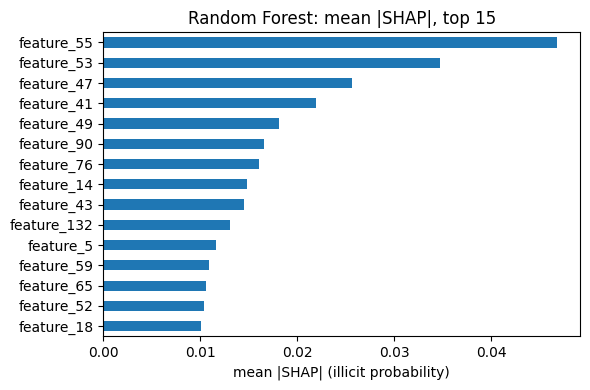

In [3]:
import shap

# All illicit test transactions plus an equal-sized random sample of licit ones
rng = np.random.default_rng(0)
idx = np.concatenate([np.flatnonzero(test["y"] == 1),
                      rng.choice(np.flatnonzero(test["y"] == 0), int(test["y"].sum()), replace=False)])
X = test[FEATURES].iloc[idx]
sv = shap.TreeExplainer(rf).shap_values(X, check_additivity=False)
sv = sv[:, :, 1] if sv.ndim == 3 else sv[1]          # contributions to the illicit class
importance = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)

share_local = importance[[f for f in FEATURES if f in LOCAL]].sum() / importance.sum()
print(f"Share of total |SHAP| from local features: {share_local:.1%} (they are 93 of 165 features)")
importance.head(15)[::-1].plot.barh(figsize=(6, 4), title="Random Forest: mean |SHAP|, top 15")
plt.xlabel("mean |SHAP| (illicit probability)"); plt.tight_layout(); plt.show()

### Before vs after the shutdown

For **illicit** test transactions, compare the model's score and the SHAP contributions of the top features before step 43 and from step 43 onwards. If the illicit transactions after the shutdown no longer show the patterns the model learned, the top features should push their score down instead of up.

In [4]:
ill = (test["y"].to_numpy()[idx] == 1)
aft = after[idx]
top = importance.index[:8]
rows = {
    "mean score": [rf_scores[idx][ill & ~aft].mean(), rf_scores[idx][ill & aft].mean()],
    "share flagged (score >= 0.5)": [(rf_scores[idx][ill & ~aft] >= 0.5).mean(), (rf_scores[idx][ill & aft] >= 0.5).mean()],
}
for f in top:
    j = FEATURES.index(f)
    rows[f"SHAP {f}"] = [sv[ill & ~aft, j].mean(), sv[ill & aft, j].mean()]
drift = pd.DataFrame(rows, index=["illicit, steps 35-42", "illicit, steps 43-49"]).T.round(3)
drift

,"illicit, steps 35-42","illicit, steps 43-49"
mean score,0.806,0.096
share flagged (score >= 0.5),0.864,0.018
SHAP feature_55,0.039,-0.044
SHAP feature_53,0.024,-0.039
SHAP feature_47,0.024,-0.023
SHAP feature_41,0.025,-0.014
SHAP feature_49,0.019,-0.015
SHAP feature_90,0.018,-0.007
SHAP feature_76,0.011,-0.012
SHAP feature_14,0.015,-0.007


## 3. GCN (Role 3) – how much does it use the graph?

The model definition and training settings are copied from the Role 3 notebook: 2 layers of width 64, dropout 0.3, weighted cross-entropy, early stopping on validation AP, and seed 0. As in Role 3, it trains on steps 1–29 and validates on 30–34. Features are standardised with training statistics.

In [5]:
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.utils import to_undirected, subgraph

N = len(data)
id2idx = pd.Series(np.arange(N), index=data["txId"].values)
ei_all = to_undirected(torch.tensor(np.vstack([id2idx[edges["txId1"].astype(str)].values,
                                               id2idx[edges["txId2"].astype(str)].values])), num_nodes=N)
x_all = torch.tensor(data[FEATURES].values, dtype=torch.float)
y_all = torch.tensor(data["y"].values)
t_all = torch.tensor(data["time_step"].values)

def make_graph(mask):
    ei, _ = subgraph(mask, ei_all, relabel_nodes=True, num_nodes=N)
    return Data(x=x_all[mask], edge_index=ei, y=y_all[mask], t=t_all[mask], node_id=torch.nonzero(mask).flatten())

train_g, val_g, test_g = make_graph(t_all <= 29), make_graph((t_all >= 30) & (t_all <= 34)), make_graph(t_all >= 35)
mu, sd = train_g.x.mean(0), train_g.x.std(0) + 1e-6
for g in (train_g, val_g, test_g):
    g.x = (g.x - mu) / sd
    g.labeled = g.y >= 0

class GCN(torch.nn.Module):
    def __init__(self, d, hid=64):
        super().__init__()
        self.c1, self.c2, self.out = GCNConv(d, hid), GCNConv(hid, hid), torch.nn.Linear(hid, 2)
    def forward(self, x, edge_index):
        for conv in (self.c1, self.c2):
            x = F.dropout(F.relu(conv(x, edge_index)), 0.3, self.training)
        return self.out(x)

random.seed(0); np.random.seed(0); torch.manual_seed(0)
counts = torch.bincount(train_g.y[train_g.labeled], minlength=2).float()
w = counts.sum() / (2 * counts)
gcn = GCN(len(FEATURES)); opt = torch.optim.Adam(gcn.parameters(), lr=5e-3, weight_decay=5e-4)

@torch.no_grad()
def scores(g, edge_index=None):
    gcn.eval()
    return torch.softmax(gcn(g.x, g.edge_index if edge_index is None else edge_index), 1)[:, 1]

best, bad, state = -1, 0, None
for epoch in range(500):
    gcn.train(); opt.zero_grad()
    F.cross_entropy(gcn(train_g.x, train_g.edge_index)[train_g.labeled], train_g.y[train_g.labeled], weight=w).backward()
    opt.step()
    ap = average_precision_score(val_g.y[val_g.labeled], scores(val_g)[val_g.labeled])
    if ap > best:
        best, bad, state = ap, 0, {k: v.clone() for k, v in gcn.state_dict().items()}
    elif (bad := bad + 1) >= 50:
        break
gcn.load_state_dict(state)
print(f"stopped after {epoch + 1} epochs, best validation AP {best:.3f}")

stopped after 232 epochs, best validation AP 0.865


In [6]:
# Graph ablation: same trained weights, test graph with every edge removed
yt = test_g.y[test_g.labeled].numpy()
with_graph = scores(test_g)[test_g.labeled].numpy()
no_graph = scores(test_g, torch.empty(2, 0, dtype=torch.long))[test_g.labeled].numpy()
print(f"GCN test AP with edges:    {average_precision_score(yt, with_graph):.3f}")
print(f"GCN test AP without edges: {average_precision_score(yt, no_graph):.3f}")

GCN test AP with edges:    0.485
GCN test AP without edges: 0.488


### GNNExplainer on confidently flagged illicit transactions

For the 5 illicit test transactions with the highest GCN score, GNNExplainer learns soft masks over node features and edges that keep the prediction. A 2-layer GCN only sees the 2-hop neighbourhood, but its degree normalisation also depends on the edges of the 2-hop nodes. The 3-hop neighbourhood is therefore extracted first. This keeps the prediction exactly the same, which is checked, and makes the explanation much faster.

In [7]:
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.utils import k_hop_subgraph

explainer = Explainer(gcn, algorithm=GNNExplainer(epochs=200), explanation_type="model",
                      node_mask_type="attributes", edge_mask_type="object",
                      model_config=dict(mode="multiclass_classification", task_level="node", return_type="raw"))

all_scores = scores(test_g).numpy()
candidates = np.flatnonzero((test_g.y == 1).numpy())
chosen = candidates[np.argsort(-all_scores[candidates])[:5]]

rows, feature_mass = [], pd.Series(0.0, index=FEATURES)
torch.manual_seed(0)
for node in chosen:
    subset, ei, mapping, _ = k_hop_subgraph(int(node), 3, test_g.edge_index, relabel_nodes=True, num_nodes=test_g.num_nodes)
    x = test_g.x[subset]
    gcn.eval()
    assert torch.allclose(torch.softmax(gcn(x, ei), 1)[mapping, 1], torch.tensor(all_scores[node]), atol=1e-5)
    exp = explainer(x, ei, index=mapping)
    own = exp.node_mask[mapping].flatten()                      # feature mask of the explained node
    feature_mass += pd.Series(own.numpy(), index=FEATURES)
    rows.append({
        "txId": data["txId"].iloc[int(test_g.node_id[node])],
        "time_step": int(test_g.t[node]),
        "score": round(float(all_scores[node]), 3),
        "nodes in 3-hop subgraph": len(subset), "edges": ei.size(1),
        "edges with mask > 0.5": int((exp.edge_mask > 0.5).sum()),
        "own-node share of feature mask": round(float(own.sum() / exp.node_mask.sum()), 3),
        "local share of own mask": round(float(own[:93].sum() / own.sum()), 3),
    })
pd.DataFrame(rows)

,txId,time_step,score,nodes in 3-hop subgraph,edges,edges with mask > 0.5,own-node share of feature mask,local share of own mask
0,75078587,46,1.000,412,904,0,0.012,0.570
1,31168385,40,1.000,387,1190,1,0.016,0.483
2,12829644,38,1.000,4,6,2,0.360,0.513
3,115949445,38,1.000,60,126,3,0.354,0.514
4,73000845,42,0.999,49,102,8,0.054,0.496


In [8]:
print("Features most used by GNNExplainer for these 5 transactions (mean mask):")
(feature_mass / len(chosen)).sort_values(ascending=False).head(10).round(3)

Features most used by GNNExplainer for these 5 transactions (mean mask):


feature_142    0.583
feature_143    0.567
feature_2      0.470
feature_148    0.416
feature_112    0.407
feature_115    0.382
feature_151    0.366
feature_91     0.350
feature_150    0.347
feature_55     0.346
dtype: float64

## 4. Interpretation

The numbers above are for these models only. The written interpretation, with numbers from a full run, is in [docs/RESULTS_AND_INTERPRETATION.md](../docs/RESULTS_AND_INTERPRETATION.md).